# EDA 4 — Tourism Monthly (Monash, Zenodo 4656096)
**Nguồn:** https://zenodo.org/records/4656096 · **License:** CC BY 4.0 · **Paper gốc:** Athanasopoulos, Hyndman, Song & Wu (2011), *The tourism forecasting competition*, IJF 27(3):822–844, DOI 10.1016/j.ijforecast.2010.04.009. Phân phối qua Monash Time Series Forecasting Archive (Godahewa et al., 2021, arXiv 2105.06643).

366 chuỗi du lịch theo tháng, dài khác nhau, chân trời dự báo chuẩn 24 tháng, không có biến ngoại sinh. Vì nhiều chuỗi, thống kê được tính **theo từng chuỗi** rồi tóm tắt phân phối.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from eda_utils import *
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 80
RAW = ROOT / 'data' / 'raw'
SUMMARY = {}  # các số chính, lưu ra reports/ để notebook so sánh dùng lại

## 1. Đọc dữ liệu (định dạng .tsf), shape, kiểu

In [2]:
df = read_tsf(RAW/'tourism_monthly_dataset.tsf')
print('shape (dạng dài):', df.shape, '| số chuỗi:', df.series.nunique()); display(df.head(3)); display(overview(df))
print('Header .tsf:'); print(''.join(l for l in open(RAW/'tourism_monthly_dataset.tsf', encoding='latin1') if l.startswith('@') and 'data' not in l))
SUMMARY.update(dataset='tourism', rows=len(df), cols=1, freq='tháng', n_series=df.series.nunique())

shape (dạng dài): (109280, 3) | số chuỗi: 366


,series,t,value
0,T1,1979-01-01,1149.8700
1,T1,1979-02-01,1053.8002
2,T1,1979-03-01,1388.8798


,dtype,n_missing,pct_missing,n_unique
series,str,0,0.0,366
t,datetime64[us],0,0.0,345
value,float64,0,0.0,23015


Header .tsf:
@relation Tourism
@attribute series_name string
@attribute start_timestamp date
@frequency monthly
@horizon 24
@missing false
@equallength false



## 2. Độ dài chuỗi, khoảng thời gian, thiếu, trùng

count    366.0
mean     298.6
std       55.7
min       91.0
25%      264.0
50%      330.0
75%      333.0
max      333.0
Name: n, dtype: float64

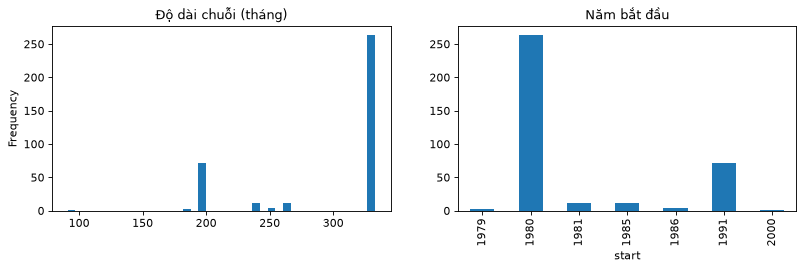

Bắt đầu sớm nhất/muộn nhất: 1979-01-01 2000-01-01 | kết thúc: 1994-07-01 2007-09-01
NA: 0 | chuỗi có số 0: 61 | tổng số 0: 574 | mốc trùng trong chuỗi: 0
Chuỗi ngắn hơn 24+24 tháng (khó vừa có train vừa test 24): 0


In [3]:
per = df.groupby('series').agg(n=('value','size'), start=('t','min'), end=('t','max'), mean=('value','mean'), std=('value','std'),
        min=('value','min'), n_zero=('value', lambda v: (v==0).sum()), n_na=('value', lambda v: v.isna().sum()))
per['cv'] = per['std']/per['mean']
display(per.n.describe().round(1))
fig, ax = plt.subplots(1,2, figsize=(12,3)); per.n.plot.hist(bins=40, ax=ax[0], title='Độ dài chuỗi (tháng)'); per.start.dt.year.value_counts().sort_index().plot.bar(ax=ax[1], title='Năm bắt đầu'); plt.show()
print('Bắt đầu sớm nhất/muộn nhất:', per.start.min().date(), per.start.max().date(), '| kết thúc:', per.end.min().date(), per.end.max().date())
print('NA:', per.n_na.sum(), '| chuỗi có số 0:', (per.n_zero>0).sum(), '| tổng số 0:', per.n_zero.sum(), '| mốc trùng trong chuỗi:', df.duplicated(['series','t']).sum())
print('Chuỗi ngắn hơn 24+24 tháng (khó vừa có train vừa test 24):', (per.n < 48).sum())
SUMMARY.update(start=per.start.min(), end=per.end.max(), missing_steps=0, dup_ts=int(df.duplicated(['series','t']).sum()), n_na=int(per.n_na.sum()),
               len_min=int(per.n.min()), len_median=float(per.n.median()), len_max=int(per.n.max()))

In [4]:
print(f"Nhận xét: {len(per)} chuỗi, tổng {len(df)} quan sát; độ dài từ {per.n.min()} đến {per.n.max()} tháng (trung vị {per.n.median():.0f}). "
      f"Lịch không đồng bộ: bắt đầu từ {per.start.min().year} đến {per.start.max().year} → không nên ghép thành ma trận theo ngày lịch; xử lý theo chỉ số tương đối hoặc padding/mask. "
      f"{per.n_na.sum()} NA, {(per.n_zero>0).sum()} chuỗi chứa số 0 ({per.n_zero.sum()} điểm).")

Nhận xét: 366 chuỗi, tổng 109280 quan sát; độ dài từ 91 đến 333 tháng (trung vị 330). Lịch không đồng bộ: bắt đầu từ 1979 đến 2000 → không nên ghép thành ma trận theo ngày lịch; xử lý theo chỉ số tương đối hoặc padding/mask. 0 NA, 61 chuỗi chứa số 0 (574 điểm).


## 3. Thống kê mô tả & quy mô theo chuỗi

,mean,std,min,cv
count,366.00,366.00,366.00,366.00
mean,10855.17,6734.87,2063.56,0.74
std,31952.76,23881.04,8452.79,0.28
min,48.15,37.28,0.00,0.19
25%,572.11,416.44,15.25,0.53
50%,1650.95,1182.55,182.00,0.71
75%,6761.35,4451.90,918.00,0.91
max,317448.82,349705.93,125100.00,1.73


Tỉ lệ mean lớn nhất / nhỏ nhất giữa các chuỗi: 6592.9


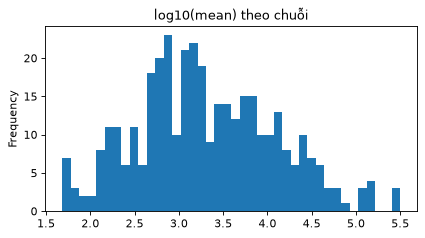

In [5]:
display(per[['mean','std','min','cv']].describe().round(2))
print('Tỉ lệ mean lớn nhất / nhỏ nhất giữa các chuỗi:', round(per['mean'].max()/per['mean'].min(),1))
plt.figure(figsize=(6,3)); np.log10(per['mean']).plot.hist(bins=40, title='log10(mean) theo chuỗi'); plt.show()
SUMMARY.update(target_mean=round(df.value.mean(),1), target_cv=round(per.cv.median(),3))

In [6]:
print(f"Nhận xét: mean theo chuỗi trải từ {per['mean'].min():.1f} đến {per['mean'].max():.0f} (chênh {per['mean'].max()/per['mean'].min():.0f} lần) → BẮT BUỘC chuẩn hoá theo từng chuỗi (scaling per-series) và dùng metric không phụ thuộc thang đo (MASE/sMAPE) như cuộc thi gốc. CV trung vị {per.cv.median():.2f}.")

Nhận xét: mean theo chuỗi trải từ 48.2 đến 317449 (chênh 6593 lần) → BẮT BUỘC chuẩn hoá theo từng chuỗi (scaling per-series) và dùng metric không phụ thuộc thang đo (MASE/sMAPE) như cuộc thi gốc. CV trung vị 0.71.


## 4. Phân phối & độ lệch theo chuỗi

,sk_skew,sk_kurt
count,366.000,366.000
mean,1.205,2.038
std,0.658,3.164
min,-0.751,-1.283
25%,0.739,0.043
50%,1.116,1.042
75%,1.630,3.063
max,3.801,28.256


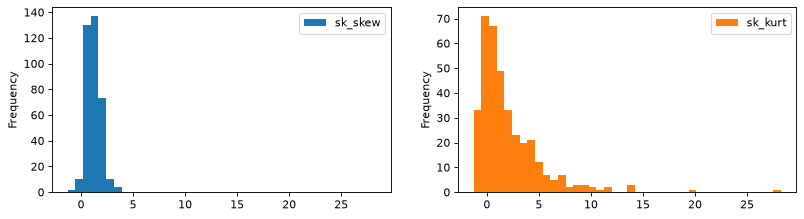

Skew của toàn bộ giá trị gộp: 13.04 | % chuỗi skew>1: 57.1


In [7]:
sk = df.groupby('series').value.agg(sk_skew='skew', sk_kurt=lambda v: v.kurt())
display(sk.describe().round(3)); sk.plot.hist(bins=40, subplots=True, layout=(1,2), figsize=(12,3), sharex=False); plt.show()
print('Skew của toàn bộ giá trị gộp:', round(df.value.skew(),2), '| % chuỗi skew>1:', round((sk.sk_skew>1).mean()*100,1))
SUMMARY.update(target_skew=round(sk.sk_skew.median(),3), target_kurt=round(sk.sk_kurt.median(),3))

In [8]:
print(f"Nhận xét: skew trung vị theo chuỗi = {sk.sk_skew.median():.2f}, kurtosis trung vị = {sk.sk_kurt.median():.2f}; {(sk.sk_skew>1).mean()*100:.1f}% chuỗi có skew>1. Gộp tất cả giá trị cho skew {df.value.skew():.1f} — con số này chủ yếu phản ánh chênh lệch quy mô giữa chuỗi, không phải hình dạng từng chuỗi.")

Nhận xét: skew trung vị theo chuỗi = 1.12, kurtosis trung vị = 1.04; 57.1% chuỗi có skew>1. Gộp tất cả giá trị cho skew 13.0 — con số này chủ yếu phản ánh chênh lệch quy mô giữa chuỗi, không phải hình dạng từng chuỗi.


## 5. Outlier theo chuỗi (IQR 1.5 trên phần dư STL)

In [9]:
from statsmodels.tsa.seasonal import STL
rows = []
for name, v in df.groupby('series').value:
    v = v.reset_index(drop=True)
    if len(v) < 36: continue
    r = STL(v, period=12).fit(); e = r.resid; q1, q3 = e.quantile([.25,.75]); i = q3-q1
    ft = max(0, 1-e.var()/(r.trend+e).var()); fs = max(0, 1-e.var()/(r.seasonal+e).var())
    rows.append({'series': name, 'outlier_pct': ((e<q1-1.5*i)|(e>q3+1.5*i)).mean()*100, 'trend_strength': ft, 'seasonal_strength': fs})
dec = pd.DataFrame(rows).set_index('series'); display(dec.describe().round(3))
SUMMARY['target_outlier_pct'] = round(dec.outlier_pct.median(),3)
print(f"Nhận xét: tính trên {len(dec)} chuỗi; tỉ lệ outlier phần dư trung vị {dec.outlier_pct.median():.2f}%, lớn nhất {dec.outlier_pct.max():.2f}% (chuỗi {dec.outlier_pct.idxmax()}).")

,outlier_pct,trend_strength,seasonal_strength
count,366.000,366.000,366.000
mean,8.322,0.887,0.818
std,5.499,0.121,0.149
min,0.503,0.327,0.389
25%,4.214,0.853,0.728
50%,6.970,0.928,0.859
75%,10.941,0.969,0.938
max,30.330,0.996,0.995


Nhận xét: tính trên 366 chuỗi; tỉ lệ outlier phần dư trung vị 6.97%, lớn nhất 30.33% (chuỗi T228).


## 6. Xu hướng & mùa vụ

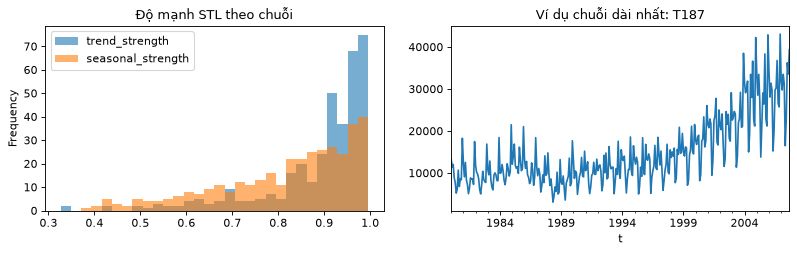

{'trend_strength': 0.928, 'seasonal_strength': 0.859} | % chuỗi mùa vụ mạnh (>0.6): 89.6


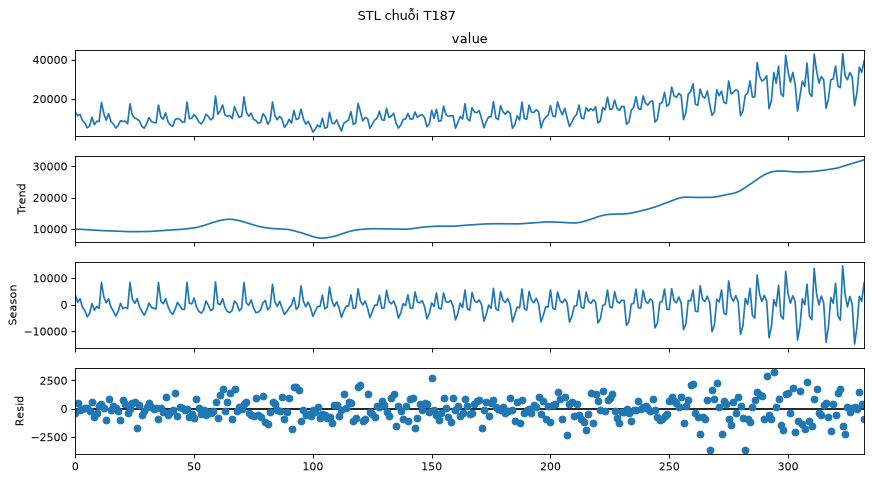

In [10]:
fig, ax = plt.subplots(1,2, figsize=(12,3))
dec[['trend_strength','seasonal_strength']].plot.hist(bins=30, alpha=.6, ax=ax[0], title='Độ mạnh STL theo chuỗi')
ex = per.n.idxmax(); df[df.series==ex].set_index('t').value.plot(ax=ax[1], title=f'Ví dụ chuỗi dài nhất: {ex}'); plt.show()
print(dec[['trend_strength','seasonal_strength']].median().round(3).to_dict(), '| % chuỗi mùa vụ mạnh (>0.6):', round((dec.seasonal_strength>.6).mean()*100,1))
SUMMARY.update(trend_strength=round(dec.trend_strength.median(),3), seasonal_strength=round(dec.seasonal_strength.median(),3))
_ = stl_strength(df[df.series==ex].value.reset_index(drop=True), period=12, title=f'STL chuỗi {ex}')

In [11]:
print(f"Nhận xét: trung vị độ mạnh mùa vụ (period 12) = {dec.seasonal_strength.median():.2f}, xu hướng = {dec.trend_strength.median():.2f}; {(dec.seasonal_strength>.6).mean()*100:.1f}% chuỗi có mùa vụ mạnh (>0.6) → baseline seasonal naive (lag 12) là bắt buộc.")

Nhận xét: trung vị độ mạnh mùa vụ (period 12) = 0.86, xu hướng = 0.93; 89.6% chuỗi có mùa vụ mạnh (>0.6) → baseline seasonal naive (lag 12) là bắt buộc.


## 7. ACF/PACF (gộp theo chuỗi)

,lag1,lag2,lag12,lag24
count,366.000,366.000,366.000,366.000
mean,0.711,0.589,0.847,0.799
std,0.171,0.207,0.136,0.164
min,0.090,-0.020,0.288,0.110
25%,0.610,0.437,0.798,0.721
50%,0.746,0.612,0.891,0.847
75%,0.848,0.748,0.946,0.922
max,0.976,0.965,0.990,0.986


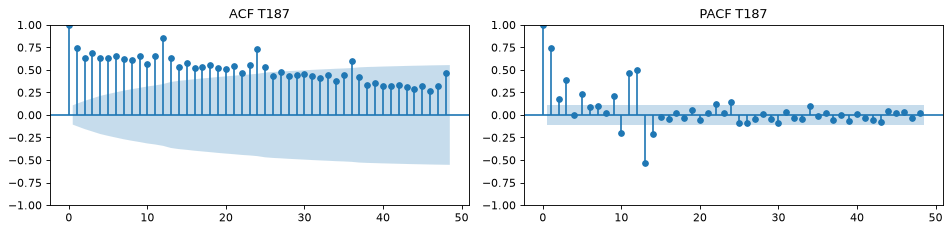

Nhận xét: trung vị ACF theo chuỗi: lag1=0.75, lag12=0.89, lag24=0.85 → đỉnh ở lag 12 xác nhận mùa vụ năm.


In [12]:
acs = df.groupby('series').value.apply(lambda v: pd.Series(autocorrs(v.reset_index(drop=True), [1,2,12,24]))).unstack()
display(acs.describe().round(3)); SUMMARY['acf'] = acs.median().round(3).to_dict()
acf_pacf(df[df.series==ex].value.reset_index(drop=True), lags=48, title=ex)
print(f"Nhận xét: trung vị ACF theo chuỗi: lag1={acs.lag1.median():.2f}, lag12={acs.lag12.median():.2f}, lag24={acs.lag24.median():.2f} → đỉnh ở lag 12 xác nhận mùa vụ năm.")

## 8. Kiểm định dừng theo chuỗi
(Không có biến ngoại sinh nên bỏ phần tương quan ngoại sinh.)

In [13]:
sr = pd.DataFrame([stationarity(v.reset_index(drop=True), n) for n, v in df.groupby('series').value])
vc = sr['kết luận'].value_counts(); display(vc); display(sr[['ADF_p','KPSS_p(bị chặn 0.01-0.1)']].describe().round(3))
SUMMARY['stationarity'] = vc.to_dict(); SUMMARY['top_exog'] = 'không có'
print(f"Nhận xét: trên {len(sr)} chuỗi: " + ', '.join(f'{k}: {v}' for k, v in vc.items()) + ". Phần lớn chuỗi cần sai phân/chuẩn hoá trước khi dùng mô hình giả định dừng.")

kết luận
không dừng                                                                                           358
trái chiều: ADF nói không dừng, KPSS nói dừng (có thể dừng quanh xu hướng)                             5
dừng                                                                                                   2
trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân)      1
Name: count, dtype: int64

,ADF_p,KPSS_p(bị chặn 0.01-0.1)
count,366.000,366.000
mean,0.793,0.012
std,0.239,0.012
min,0.001,0.010
25%,0.669,0.010
50%,0.890,0.010
75%,0.984,0.010
max,1.000,0.100


Nhận xét: trên 366 chuỗi: không dừng: 358, trái chiều: ADF nói không dừng, KPSS nói dừng (có thể dừng quanh xu hướng): 5, dừng: 2, trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân): 1. Phần lớn chuỗi cần sai phân/chuẩn hoá trước khi dùng mô hình giả định dừng.


In [14]:
import json; (ROOT/'reports').mkdir(exist_ok=True)
json.dump(SUMMARY, open(ROOT/'reports'/f"summary_{SUMMARY['dataset']}.json", 'w'), ensure_ascii=False, indent=1, default=str)
SUMMARY

{'dataset': 'tourism',
 'rows': 109280,
 'cols': 1,
 'freq': 'tháng',
 'n_series': 366,
 'start': Timestamp('1979-01-01 00:00:00'),
 'end': Timestamp('2007-09-01 00:00:00'),
 'missing_steps': 0,
 'dup_ts': 0,
 'n_na': 0,
 'len_min': 91,
 'len_median': 330.0,
 'len_max': 333,
 'target_mean': np.float64(9969.2),
 'target_cv': np.float64(0.714),
 'target_skew': np.float64(1.116),
 'target_kurt': np.float64(1.042),
 'target_outlier_pct': np.float64(6.97),
 'trend_strength': np.float64(0.928),
 'seasonal_strength': np.float64(0.859),
 'acf': {'lag1': 0.746, 'lag2': 0.612, 'lag12': 0.891, 'lag24': 0.847},
 'stationarity': {'không dừng': 358,
  'trái chiều: ADF nói không dừng, KPSS nói dừng (có thể dừng quanh xu hướng)': 5,
  'dừng': 2,
  'trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân)': 1},
 'top_exog': 'không có'}